# 07. Кривые процесса и средовые эффекты


In [1]:
knitr::opts_chunk$set(
  echo = FALSE,
  message = FALSE,
  warning = FALSE,
  fig.align = "center",
  fig.width = 9,
  fig.height = 5
)


# О документе

Отчёт подбирает полином «измерение ~ возраст процесса», отсекает выбросы по остаткам и проверяет, какие средовые факторы стоит класть в смешанную модель как фиксированные эффекты.

| | |
|---|---|
| **Данные** | `data/process_curve.csv`, `data/environment_raw.csv`, `data/process_events.csv` |
| **Цель** | Выбрать степень полинома, очистить кривую, оценить связь `trait` с температурой, давлением, влажностью, заводом, годом и сезоном |
| **Результат** | Спецификация эффектов: какие ковариаты оставлять в модели качества, какие центрировать, какие отбросить |


In [2]:
library(dplyr)
library(stringr)
library(ggplot2)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



In [3]:
curve <- read.csv("data/process_curve.csv")
env_raw <- read.csv("data/environment_raw.csv")
events <- read.csv("data/process_events.csv")
curve$factory <- as.factor(curve$factory)
curve$mark <- as.factor(curve$mark)
curve$type <- as.factor(curve$type)


# 1. Кривая процесса

Зависимость измеренной массы партии `mass` от возраста процесса `age`. Сначала смотрим сырой разброс по заводам и маркам.


In [4]:
summary(curve)


    item_id          age              mass            factory   
 Min.   :   1   Min.   :  3.00   Min.   :  6.135   Завод_А:756  
 1st Qu.: 732   1st Qu.: 35.00   1st Qu.: 16.657   Завод_Б:651  
 Median :1447   Median : 52.00   Median : 20.848   Завод_В:393  
 Mean   :1473   Mean   : 58.96   Mean   : 23.338                
 3rd Qu.:2213   3rd Qu.: 76.00   3rd Qu.: 26.078                
 Max.   :3000   Max.   :229.00   Max.   :149.385                
         mark     type   
 Марка_M   :347   A:974  
 Марка_X   :427   B:826  
 Марка_Y   :419          
 Марка_Z   :435          
 Неизвестно:172          
                         


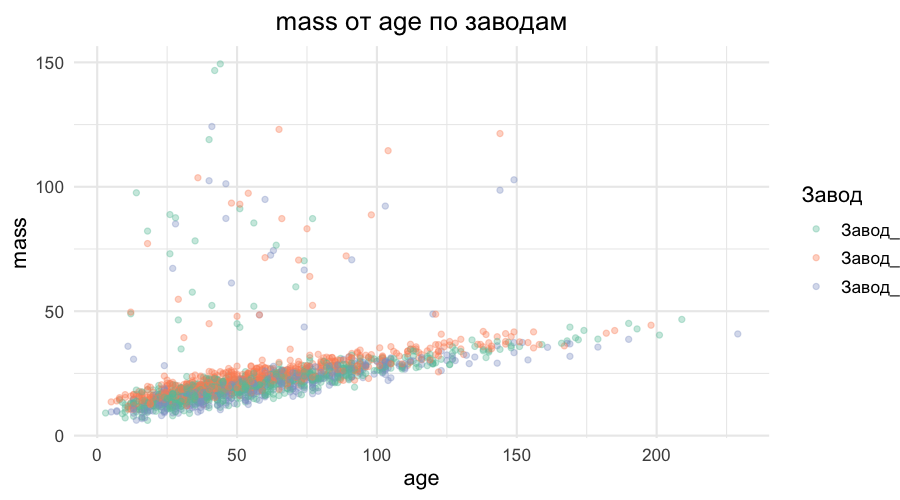

In [5]:
ggplot(curve, aes(x = age, y = mass, color = factory)) +
  geom_point(alpha = 0.35, size = 1.4) +
  scale_color_brewer(palette = "Set2") +
  labs(title = "mass от age по заводам", x = "age", y = "mass", color = "Завод") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# 2. Выбор степени полинома

10-fold CV для степеней `1…5`. На каждом фолде модель учится на train, MSE считается на test. Берём степень с наименьшим средним MSE.


In [6]:
set.seed(42)
K <- 10
max_degree <- 5
shuffled <- curve[sample(nrow(curve)), ]
folds <- cut(seq_len(nrow(shuffled)), breaks = K, labels = FALSE)
mse <- matrix(NA_real_, nrow = K, ncol = max_degree)

for (i in seq_len(K)) {
  test_idx <- which(folds == i)
  test_data <- shuffled[test_idx, ]
  train_data <- shuffled[-test_idx, ]
  for (j in seq_len(max_degree)) {
    fit <- lm(mass ~ poly(age, j, raw = TRUE), data = train_data)
    pred <- predict(fit, newdata = test_data)
    mse[i, j] <- mean((pred - test_data$mass)^2)
  }
}

cv_mse <- data.frame(degree = seq_len(max_degree), mse = colMeans(mse))
best_degree <- cv_mse$degree[which.min(cv_mse$mse)]
cv_mse
best_degree


  degree      mse
1      1 142.6722
2      2 142.6158
3      3 142.7627
4      4 142.6809
5      5 142.8352


[1] 2


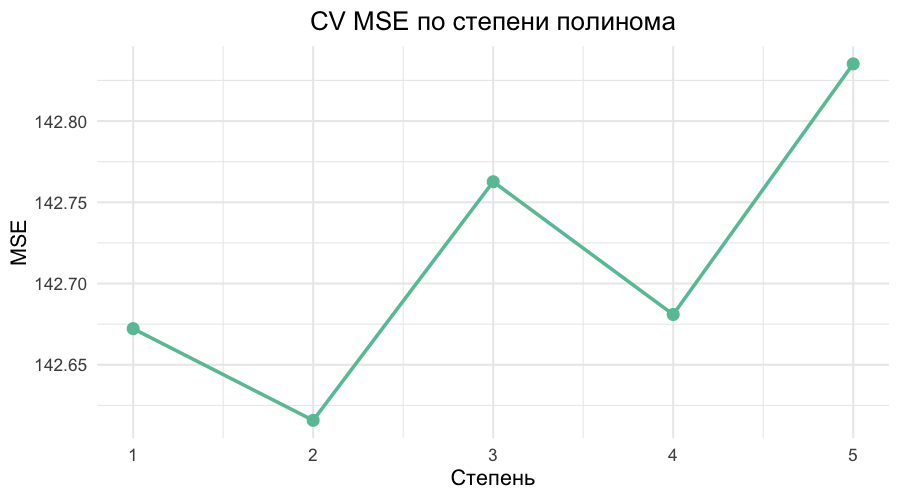

In [7]:
ggplot(cv_mse, aes(x = degree, y = mse)) +
  geom_line(color = "#66C2A5", linewidth = 1) +
  geom_point(size = 3, color = "#66C2A5") +
  labs(title = "CV MSE по степени полинома", x = "Степень", y = "MSE") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


Полином степени 2 обычно достаточен: кривая процесса вогнутая, старшие степени на CV не выигрывают и только ловят выбросы.


In [8]:
best <- lm(mass ~ poly(age, 2, raw = TRUE), data = curve)
summary(best)$coefficients
curve$fitted <- predict(best)
curve$resid <- residuals(best)


                               Estimate   Std. Error   t value     Pr(>|t|)
(Intercept)               12.1246517654 0.9549762109 12.696287 1.963157e-35
poly(age, 2, raw = TRUE)1  0.2096548046 0.0271363086  7.725988 1.832080e-14
poly(age, 2, raw = TRUE)2 -0.0002499735 0.0001646251 -1.518441 1.290792e-01


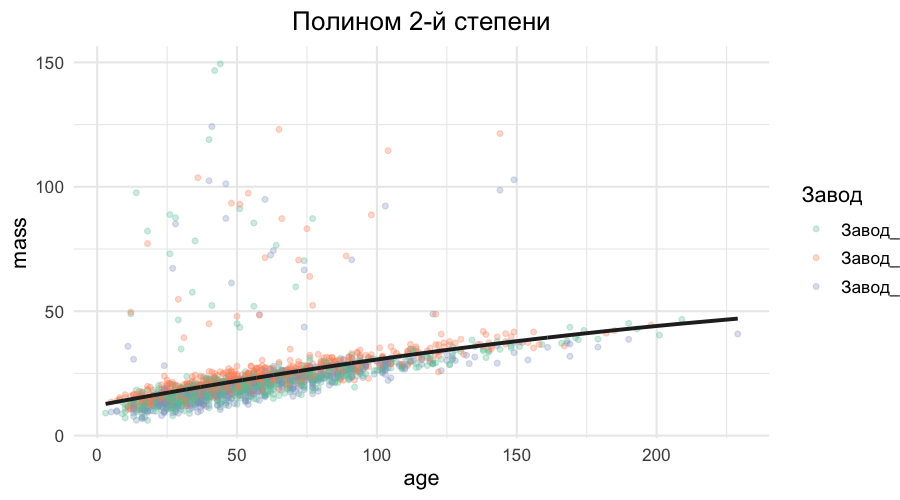

In [9]:
ggplot(curve, aes(x = age, y = mass)) +
  geom_point(aes(color = factory), alpha = 0.3, size = 1.3) +
  geom_line(aes(y = fitted), color = "grey15", linewidth = 1.1) +
  scale_color_brewer(palette = "Set2") +
  labs(title = "Полином 2-й степени", x = "age", y = "mass", color = "Завод") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


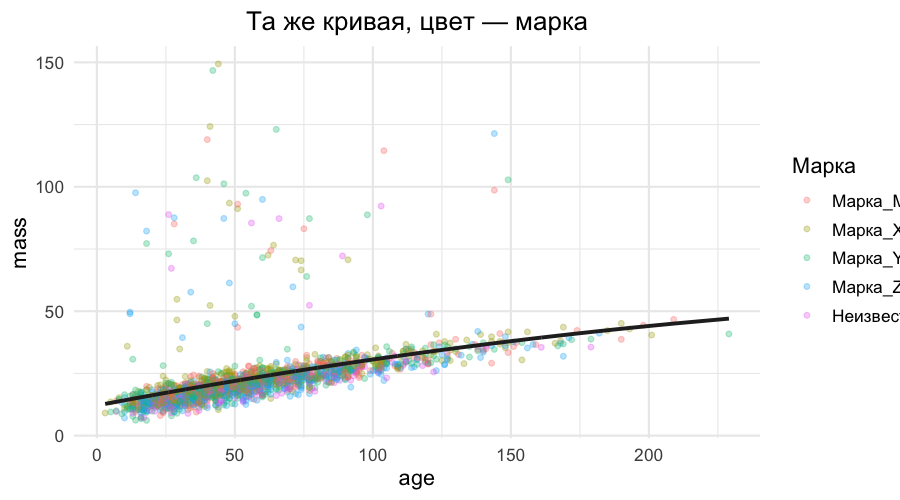

In [10]:
ggplot(curve, aes(x = age, y = mass)) +
  geom_point(aes(color = mark), alpha = 0.3, size = 1.3) +
  geom_line(aes(y = fitted), color = "grey15", linewidth = 1.1) +
  labs(title = "Та же кривая, цвет — марка", x = "age", y = "mass", color = "Марка") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# 3. Фильтр выбросов по остаткам

Точки с `|resid| > 2.5 · sd(resid)` считаем сбоем измерения, а не формой кривой. Их убираем до смешанной модели.


In [11]:
resid_cut <- 2.5 * sd(curve$resid)
curve_clean <- curve %>% filter(abs(resid) <= resid_cut)
c(
  n_raw = nrow(curve),
  n_clean = nrow(curve_clean),
  n_removed = nrow(curve) - nrow(curve_clean),
  resid_sd = sd(curve$resid)
)


     n_raw    n_clean  n_removed   resid_sd 
1800.00000 1750.00000   50.00000   11.92528 


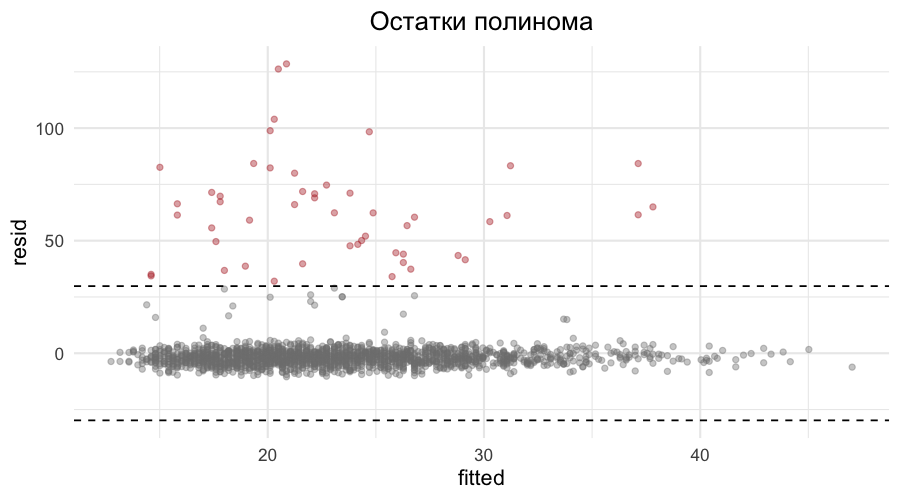

In [12]:
ggplot(curve, aes(x = fitted, y = resid, color = abs(resid) > resid_cut)) +
  geom_point(alpha = 0.4, size = 1.4) +
  geom_hline(yintercept = c(-resid_cut, resid_cut), linetype = "dashed") +
  scale_color_manual(values = c("grey50", "firebrick"), guide = "none") +
  labs(title = "Остатки полинома", x = "fitted", y = "resid") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# 4. Разбор сырой среды

Файл `environment_raw.csv` имитирует выгрузку метеостанции: дата в `дд.мм.гггг чч:мм`, видимость текстом (`10.0 и более`), направление ветра фразой. Приводим к числам и суточным средним по площадке.


In [13]:
env <- env_raw %>%
  mutate(
    datetime = as.POSIXct(datetime, format = "%d.%m.%Y %H:%M"),
    date = as.Date(datetime),
    hour = as.numeric(format(datetime, "%H")),
    VV = case_when(
      VV == "10.0 и более" ~ "10",
      VV == "менее 0.1" ~ "0.1",
      VV == "менее 0.05" ~ "0.05",
      str_detect(VV, fixed("<")) ~ NA_character_,
      TRUE ~ as.character(VV)
    ),
    DD = case_when(
      DD == "Ветер, дующий с востока" ~ "В",
      DD == "Ветер, дующий с северо-востока" ~ "СВ",
      DD == "Ветер, дующий с юго-востока" ~ "ЮВ",
      DD == "Ветер, дующий с запада" ~ "З",
      DD == "Ветер, дующий с северо-запада" ~ "СЗ",
      DD == "Ветер, дующий с юго-запада" ~ "ЮЗ",
      DD == "Ветер, дующий с севера" ~ "С",
      DD == "Ветер, дующий с юга" ~ "Ю",
      DD == "Переменное направление" ~ "Переменное",
      DD == "Штиль, безветрие" ~ "Штиль",
      DD == "" ~ NA_character_,
      TRUE ~ DD
    ),
    Ff = as.numeric(Ff),
    VV = as.numeric(VV),
    Td = as.numeric(Td)
  ) %>%
  group_by(place, date) %>%
  summarise(
    temp = mean(temp, na.rm = TRUE),
    pressure = mean(P, na.rm = TRUE),
    humidity = mean(U, na.rm = TRUE),
    wind = first(DD),
    .groups = "drop"
  )

summary(env)


    place                date                 temp            pressure     
 Length:2491        Min.   :2022-01-01   Min.   :-10.600   Min.   : 987.2  
 Class :character   1st Qu.:2022-08-11   1st Qu.:  2.100   1st Qu.:1007.3  
 Mode  :character   Median :2023-03-26   Median :  9.300   Median :1012.8  
                    Mean   :2023-03-25   Mean   :  9.266   Mean   :1012.8  
                    3rd Qu.:2023-11-04   3rd Qu.: 16.600   3rd Qu.:1018.2  
                    Max.   :2024-06-18   Max.   : 28.500   Max.   :1037.2  
    humidity         wind          
 Min.   :18.00   Length:2491       
 1st Qu.:52.00   Class :character  
 Median :62.00   Mode  :character  
 Mean   :61.47                     
 3rd Qu.:71.00                     
 Max.   :96.00                     


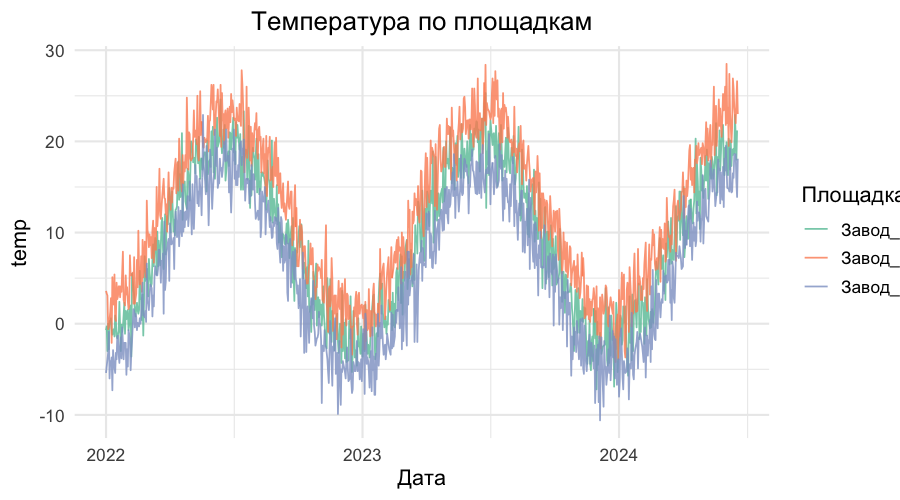

In [14]:
ggplot(env, aes(x = date, y = temp, color = place)) +
  geom_line(alpha = 0.8) +
  scale_color_brewer(palette = "Set2") +
  labs(title = "Температура по площадкам", x = "Дата", y = "temp", color = "Площадка") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# 5. Эффекты для смешанной модели

Берём события с уже сопоставленной средой. Пропуски выкидываем. Температуру, давление и влажность центрируем: нулевой уровень должен быть рабочим, а не «0 °C / 0 гПа / 0 %».


In [15]:
num_variables <- c("temp", "pressure", "humidity")
cat_variables <- c("event_year", "event_season", "factory")
base_values <- c("2023", "1", "Завод_А")
center_at <- c(temp = 10, pressure = 1013, humidity = 60)

pipe <- events %>%
  filter(complete.cases(.)) %>%
  mutate(across(all_of(cat_variables), as.factor))

for (v in num_variables) {
  pipe[[v]] <- pipe[[v]] - center_at[[v]]
}

summary(pipe)


    item_id     event_year event_season    factory         temp         
 Min.   :   1   2022:649   1:474        Завод_А:679   Min.   :-13.8900  
 1st Qu.: 738   2023:669   2:453        Завод_Б:560   1st Qu.: -5.2050  
 Median :1473   2024:282   3:345        Завод_В:361   Median :  0.2100  
 Mean   :1484              4:328                      Mean   :  0.1603  
 3rd Qu.:2236                                         3rd Qu.:  5.6150  
 Max.   :3000                                         Max.   : 14.0700  
    pressure           humidity            trait      
 Min.   :-18.1100   Min.   :-40.0000   Min.   :30.86  
 1st Qu.: -3.9500   1st Qu.: -8.2125   1st Qu.:40.36  
 Median :  0.0950   Median : -0.1200   Median :42.67  
 Mean   :  0.1065   Mean   : -0.2113   Mean   :42.69  
 3rd Qu.:  4.0200   3rd Qu.:  7.6500   3rd Qu.:45.02  
 Max.   : 20.8900   Max.   : 35.0000   Max.   :54.30  


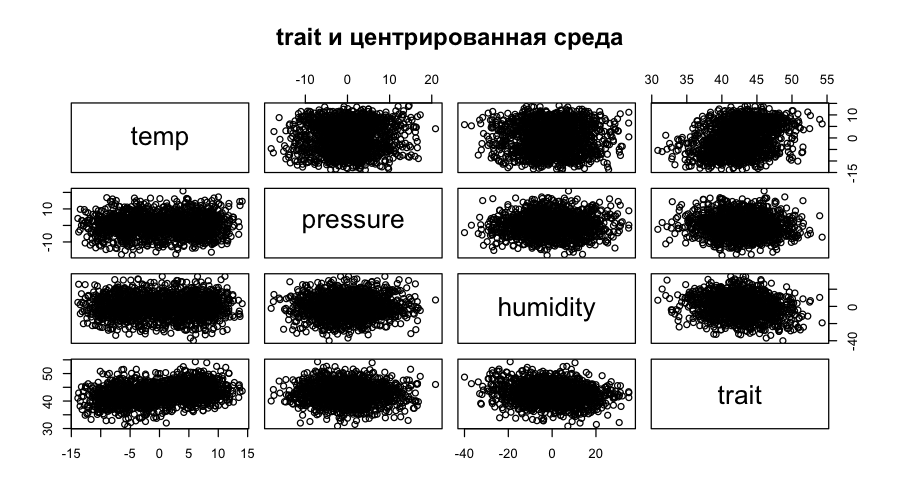

In [16]:
pairs(
  pipe[, c(num_variables, "trait")],
  main = "trait и центрированная среда"
)


## 5.1. Связь `trait` с числовыми ковариатами

Шапиро–Уилк на выборке до 2000 наблюдений. Если хотя бы одна переменная не нормальна — Кендалл, иначе Пирсон.


In [17]:
correlation_coefficient <- function(dataset, var_1, var_2) {
  x <- dataset[[var_1]]
  y <- dataset[[var_2]]
  n <- min(length(x), 2000)
  idx <- seq_len(n)
  p1 <- shapiro.test(x[idx])$p.value
  p2 <- shapiro.test(y[idx])$p.value
  if (p1 < 0.05 || p2 < 0.05) {
    ct <- cor.test(x, y, method = "kendall")
    return(c(method = "kendall", estimate = unname(ct$estimate), p_value = ct$p.value))
  }
  ct <- cor.test(x, y, method = "pearson")
  c(method = "pearson", estimate = unname(ct$estimate), p_value = ct$p.value)
}

corr_tbl <- as.data.frame(t(sapply(num_variables, function(v) {
  correlation_coefficient(pipe, v, "trait")
})))
corr_tbl$variable <- num_variables
corr_tbl <- corr_tbl[, c("variable", "method", "estimate", "p_value")]
corr_tbl


         variable  method           estimate              p_value
temp         temp kendall  0.210085512134733  2.4531333907806e-36
pressure pressure pearson -0.038338054263681    0.125303648133076
humidity humidity pearson -0.179527754840915 4.67764732156219e-13


## 5.2. Связь `trait` с категориальными эффектами

При отклонении от нормальности — Краскел–Уоллис, иначе однофакторный ANOVA.


In [18]:
category_dependency <- function(dataset, y_name, x_name) {
  y <- dataset[[y_name]]
  x <- dataset[[x_name]]
  n <- min(length(y), 2000)
  p_norm <- shapiro.test(y[seq_len(n)])$p.value
  if (p_norm < 0.05) {
    kt <- kruskal.test(y ~ x)
    return(c(test = "kruskal", statistic = unname(kt$statistic), p_value = kt$p.value))
  }
  av <- summary.aov(aov(y ~ x))[[1]]
  c(test = "anova", statistic = av[["F value"]][1], p_value = av[["Pr(>F)"]][1])
}

cat_tbl <- as.data.frame(t(sapply(cat_variables, function(v) {
  category_dependency(pipe, "trait", v)
})))
cat_tbl$variable <- cat_variables
cat_tbl <- cat_tbl[, c("variable", "test", "statistic", "p_value")]
cat_tbl


                 variable  test         statistic              p_value
event_year     event_year anova 0.611284859355209    0.542780109063676
event_season event_season anova   56.133131337256 1.70609500529071e-34
factory           factory anova  20.4299442976975 1.73377592473688e-09


Проверка, не является ли погода просто прокси сезона или года:


In [19]:
env_season <- as.data.frame(t(sapply(num_variables, function(v) {
  category_dependency(pipe, v, "event_season")
})))
env_season$variable <- num_variables
env_season


            test          statistic               p_value variable
temp     kruskal   1091.01841966752 3.23306147253208e-236     temp
pressure   anova  0.919559415263457     0.430600788563914 pressure
humidity   anova 0.0177479897353343     0.996782718823729 humidity


## 5.3. Линейные вклады

Коэффициенты после центрирования читаются как сдвиг `trait` при отклонении среды от рабочего уровня. Для категорий референс: год `2023`, сезон `1`, завод `Завод_А`.


In [20]:
num_coef <- as.data.frame(t(sapply(num_variables, function(v) {
  fit <- lm(pipe$trait ~ pipe[[v]])
  c(intercept = unname(coef(fit)[1]), slope = unname(coef(fit)[2]))
})))
num_coef$variable <- num_variables
num_coef


         intercept       slope variable
temp      42.66671  0.17037723     temp
pressure  42.69633 -0.02174213 pressure
humidity  42.68315 -0.05142974 humidity


In [21]:
cat_model_analysis <- function(effect, base_value) {
  x <- pipe[[effect]]
  x <- relevel(x, ref = base_value)
  fit <- lm(pipe$trait ~ x)
  df <- data.frame(term = names(coef(fit)), coef = as.numeric(coef(fit)))
  df$effect <- effect
  df
}

cat_coef <- do.call(
  rbind,
  mapply(cat_model_analysis, cat_variables, base_values, SIMPLIFY = FALSE)
)
cat_coef


                      term        coef       effect
event_year.1   (Intercept) 42.77846188   event_year
event_year.2         x2022 -0.09108438   event_year
event_year.3         x2024 -0.26949380   event_year
event_season.1 (Intercept) 41.61899156 event_season
event_season.2          x2  1.92290689 event_season
event_season.3          x3  2.39326931 event_season
event_season.4          x4  0.07099624 event_season
factory.1      (Intercept) 43.31234757      factory
factory.2         xЗавод_Б -0.95456543      factory
factory.3         xЗавод_В -1.25975477      factory


# Заключение

Кривая `mass ~ age` хорошо описывается полиномом 2-й степени: CV не требует старших членов. Выбросы по остаткам лучше снимать до модели, иначе фиксированные эффекты завода и марки поплывут.

Среду нельзя подставлять «как в выгрузке»: видимость и ветер — текст, температура и влажность имеют рабочий ноль не в нуле шкалы. После очистки и центрирования в смешанную модель имеет смысл брать завод, сезон и температуру; давление и влажность проверять на коллинеарность с сезоном и не дублировать, если они только повторяют календарь.
